## Model Price Adder vs. Spare Capacity Metric v2
- use adder only for modeling

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

GEN_PATH = '../../01_data/2_cleaned/generation/hourly_solar_wind_generation_2020_2025.parquet'
LOAD_PATH = '../../01_data/2_cleaned/load/total_load_20201231_20260526.csv'
CAPACITY_PATH = '../../01_data/2_cleaned/generation/ERCOT nonRE capacity 2020-2025.csv'
NG_PATH = '../../01_data/3_analysis/ng_price/ng_prices_monthly.csv'
TEMP_PATH = '../../01_data/2_cleaned/weather/Texas_hourly_temp_2021_2025.csv'

OUTAGE_PATH = '../../01_data/2_cleaned/outage/archive_1h_ahead_outage_20210101_2026_0924.parquet'
AGG_PRICE_PATH = '../../01_data/3_analysis/price incentive metrics/rtm_adder_aggregated_20210101_20251203.csv'

OUT_DIR = Path('../../01_data/3_analysis')

In [2]:
df_outage = pd.read_parquet(OUTAGE_PATH)
df_outage['datetime'] = pd.to_datetime(df_outage['datetime'])
df_outage.head()

,datetime,totalResourceMW
0,2021-01-01 01:00:00,7754.0
1,2021-01-01 02:00:00,7681.0
2,2021-01-01 03:00:00,7681.0
3,2021-01-01 04:00:00,7681.0
4,2021-01-01 05:00:00,7681.0


In [3]:
df_agg_price = pd.read_csv(AGG_PRICE_PATH)
df_agg_price['datetime'] = pd.to_datetime(df_agg_price['datetime'])
df_agg_price.head()

,datetime,rtm_price,RTRSVPOR,RTRSVPOFF,RTRDP,price_wo_adders
0,2021-01-01 01:00:00,18.173500,0.0,0.0,0.0,18.173500
1,2021-01-01 02:00:00,20.960833,0.0,0.0,0.0,20.960833
2,2021-01-01 03:00:00,20.779667,0.0,0.0,0.0,20.779667
3,2021-01-01 04:00:00,16.416667,0.0,0.0,0.0,16.416667
4,2021-01-01 05:00:00,18.075333,0.0,0.0,0.0,18.075333


In [4]:
df_gen = pd.read_parquet(GEN_PATH)
df_gen['datetime'] = pd.to_datetime(df_gen['datetime'])
df_gen.head()

,datetime,renewable_gen
0,2020-01-01 01:00:00,12832.85
1,2020-01-01 02:00:00,13328.73
2,2020-01-01 03:00:00,13920.06
3,2020-01-01 04:00:00,14443.91
4,2020-01-01 05:00:00,14713.70


In [5]:
df_load = pd.read_csv(LOAD_PATH)
df_load['datetime'] = pd.to_datetime(df_load['datetime'])
df_load.head()

,datetime,total_load
0,2020-12-31 01:00:00,39174.39
1,2020-12-31 02:00:00,38284.84
2,2020-12-31 03:00:00,37776.69
3,2020-12-31 04:00:00,37781.84
4,2020-12-31 05:00:00,38455.69


In [6]:
df_capacity = pd.read_csv(CAPACITY_PATH)
df_total_cap = df_capacity.filter(['year', 'total_mw'])
df_total_cap = df_total_cap.rename(columns={'total_mw': 'non_re_capacity'})
df_total_cap['non_re_capacity'] = df_total_cap['non_re_capacity'].astype(int)
df_total_cap

,year,non_re_capacity
0,2020,65518
1,2021,66390
2,2022,67023
3,2023,68028
4,2024,68766
5,2025,68624


In [7]:
df_ng = pd.read_csv(NG_PATH)
df_ng = df_ng[(df_ng['date']>= '2021-01-01') & (df_ng['date']<= '2025-12-03')]
df_ng['date'] = pd.to_datetime(df_ng['date'])
df_ng['month'] = df_ng['date'].dt.month
df_ng['year'] = df_ng['date'].dt.year

df_ng.head()

,date,henry_hub,citygate,elec_pwr,outlier_citygate,outlier_elec_pwr,month,year
227,2021-01-01,2.712632,2.909441,2.793834,False,False,1,2021
228,2021-02-01,5.353684,39.181118,59.614644,True,True,2,2021
229,2021-03-01,2.618261,4.393064,2.947977,False,False,3,2021
230,2021-04-01,2.662857,3.554913,3.131021,False,False,4,2021
231,2021-05-01,2.912500,3.429672,3.294798,False,False,5,2021


In [8]:
df_temp = pd.read_csv(TEMP_PATH)
df_temp

,datetime,tx_temp
0,2021-01-01 01:00:00,35.301445
1,2021-01-01 02:00:00,34.923515
2,2021-01-01 03:00:00,34.651550
3,2021-01-01 04:00:00,33.962486
4,2021-01-01 05:00:00,32.179900
...,...,...
43814,2025-12-31 20:00:00,56.684467
43815,2025-12-31 21:00:00,51.554237
43816,2025-12-31 22:00:00,50.368977
43817,2025-12-31 23:00:00,49.432446


### Aggregate price adder + metric 2 spare capacity
1. include uri points this time, because the outage data is included
2. metric2: evaluates spare capacity accounting for outage; 
    - (hourly load - hourly renewable_gen) / (non_re_capacity - hourly outage)

In [9]:
import duckdb

# price adders only
con = duckdb.connect()
df_metric = con.execute("""
   WITH Merged AS (
      SELECT
         g.datetime
         ,RTRSVPOR
         ,RTRSVPOFF
         ,RTRDP	
         ,renewable_gen
         ,total_load
         ,non_re_capacity
         ,totalResourceMW AS outage
      FROM df_gen g
      INNER JOIN df_load l ON g.datetime = l.datetime
      LEFT JOIN df_total_cap c ON YEAR(g.datetime) = c.year
      JOIN df_agg_price p ON g.datetime = p.datetime
      JOIN df_outage o ON o.datetime = g.datetime               
      )
   
   SELECT
         datetime
         ,YEAR(datetime) AS year
         ,RTRSVPOR
         ,RTRSVPOFF
         ,RTRDP
         ,(total_load - renewable_gen)/(non_re_capacity - outage) AS metric2
   FROM Merged
   ORDER BY datetime;
""").fetchdf()

df_metric

,datetime,year,RTRSVPOR,RTRSVPOFF,RTRDP,metric2
0,2021-01-01 01:00:00,2021,0.0,0.0,0.00,0.507010
1,2021-01-01 02:00:00,2021,0.0,0.0,0.00,0.494391
2,2021-01-01 03:00:00,2021,0.0,0.0,0.00,0.491019
3,2021-01-01 04:00:00,2021,0.0,0.0,0.00,0.508057
4,2021-01-01 05:00:00,2021,0.0,0.0,0.00,0.531662
...,...,...,...,...,...,...
43144,2025-12-03 19:00:00,2025,0.0,0.0,0.01,0.840561
43145,2025-12-03 20:00:00,2025,0.0,0.0,0.00,0.784120
43146,2025-12-03 21:00:00,2025,0.0,0.0,0.00,0.739089
43147,2025-12-03 22:00:00,2025,0.0,0.0,0.00,0.695477


## EDA with price adders

### Local Regression by year slices

In [10]:
import statsmodels.api as sm
def lowess_fit(x, y, color, label):
    
    # 2. Apply LOWESS local regression
    # frac: the fraction of data used when estimating each y-value (controls smoothing)
    lowess_fit = sm.nonparametric.lowess(y, x, frac=0.1)

    # Extract sorted x and predicted y values
    x_smooth = lowess_fit[:, 0]
    y_smooth = lowess_fit[:, 1]

    # plot
    plt.scatter(x, y, color='lightgray')
    plt.plot(x_smooth, y_smooth, color=color, linewidth=2, label=f"{label} LOWESS Fit")
    plt.legend()

KeyError: 'price_wo_adders'

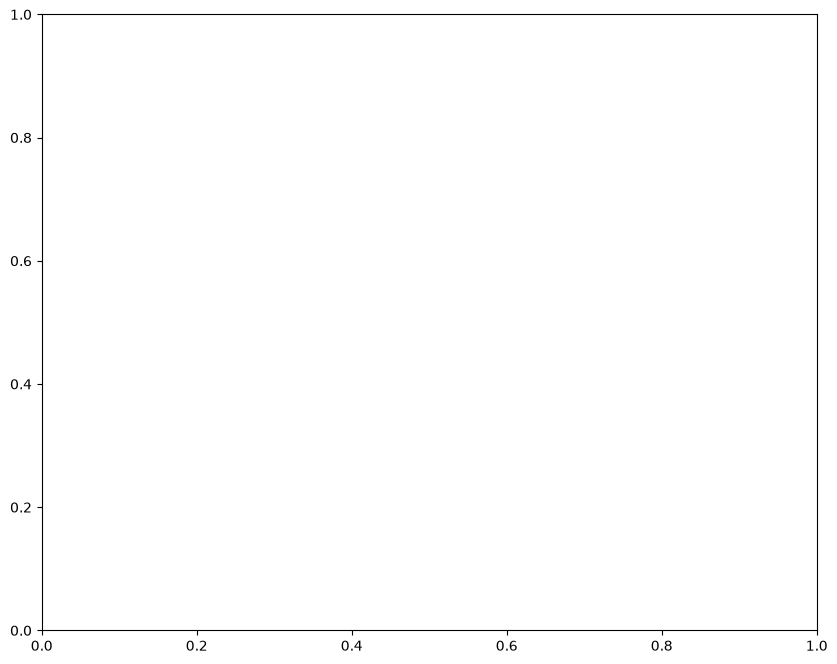

In [11]:
fig, ax = plt.subplots(figsize=(10, 8))
years = [2021, 2022, 2023, 2024, 2025]
colors = ['#FF416C', '#FF8080', '#FFAF7B', '#FFDCA6', '#FFEFBA']

for year, color in zip(years, colors):
    df_year = df_metric[df_metric['year'] == year]
    lowess_fit(df_year['metric2'], np.log(df_year['price_wo_adders']), color, year)

In [ ]:
fig, axs = plt.subplots(1, 5, figsize=(30, 5))
for i, year in enumerate(years):
    df_year = df_metric[df_metric['year'] == year]
    axs[i].scatter(df_year['metric2'], np.log(df_year['price_wo_adders']), color=colors[i])
    axs[i].set_ylim(-4, 10)
    axs[i].set_title(f'{year} rtm Price vs. Spare Capacity')

### Slice by monthly timeseries

In [ ]:
fig, ax = plt.subplots(figsize=(30, 6))
ax.plot(df_metric['datetime'] , df_metric['metric2'])

In [ ]:
df_metric.groupby('year').mean()['metric2']

In [ ]:
plt.figure(figsize=(10, 8))
df_month = df_metric.copy()
df_month['month'] = df_month['datetime'].dt.month

for year, color in zip(df_month['year'].unique(), colors):
    df = df_month[df_month['year']==year]
    df = df.groupby(df['datetime'].dt.month).mean()
    plt.plot(df['month'] , df['metric2'], color=color, label=year)
plt.legend()
plt.title('Spare Capacity Metric 2 By Month\n2021-2025')
plt.xlabel('Month')
plt.ylabel('Spare Capacity')

### Natural Gas color coding

In [ ]:
df_metric_with_ng = con.execute("""
      SELECT 
         m.datetime
         ,price_wo_adders
         ,metric2 AS capacity
         ,citygate AS ng_price
      FROM df_metric m
         LEFT JOIN df_ng n ON n.month = MONTH(m.datetime)
                           AND n.year = m.year                         
      ORDER BY n.year, n.month;
""").fetchdf()

df_metric_with_ng

In [ ]:
np.log(10)

In [ ]:
df = df_metric_with_ng.copy()
#df = df[df['ng_price'] > np.exp(1)**3]
plt.figure(figsize=(15, 13))
plt.scatter(df['capacity'], np.log(df['price_wo_adders']), c=np.log(df['ng_price']), alpha=0.8, s=10)
plt.colorbar()
plt.title('Without Adder Price (Log) vs. Spare Capacity colored by NG Price (Log)\n2021-2025')

In [ ]:
df = df_metric_with_ng.copy()
df = df.dropna()
df['ng_bins'] = pd.qcut(df['ng_price'], 10)
df_bins = df.sort_values('ng_bins')

fig, ax = plt.subplots(figsize=(10, 8))

colors10 = ['#E0F2FE', '#BAE6FD', '#7DD3FC', '#38BDF8', '#0EA5E9', '#0284C7', '#0369A1', '#075985', '#0C4A6E', '#082F49']

for bin, color in zip(df_bins['ng_bins'].unique(), colors10):
    df_bin = df_bins[df_bins['ng_bins'] == bin]
    lowess_fit(df_bin['capacity'], np.log(df_bin['price_wo_adders']), color, bin)

plt.title('RTM Price (Log) vs. Spare Capacity colored by NG Price quantiles')
plt.ylabel('RTM Price (Log)')
plt.xlabel('Spare Capacity Metric 2')

### Temp Color Coding

In [ ]:
df_metric_with_temp = con.execute("""
      SELECT 
         m.datetime
         ,ABS(tx_temp - 65) AS degree_days
         ,price_wo_adders
         ,metric2 AS capacity
      FROM df_metric m
         LEFT JOIN df_temp t ON t.datetime = m.datetime                        
      ORDER BY m.datetime;
""").fetchdf()
df_metric_with_temp

In [ ]:
df = df_metric_with_temp.copy()
plt.figure(figsize=(15, 13))
plt.scatter(df['capacity'], np.log(df['price_wo_adders']), c=df['degree_days'], alpha=0.8, s=10)
plt.colorbar()
plt.title('RTM Price vs. Spare Capacity (colored by Absolute Temperature)\n2021-2025')

In [ ]:
df = df_metric_with_temp.copy()
df = df.dropna()
df['dd_bins'] = pd.qcut(df['degree_days'], 10, duplicates='drop')
df_bins = df.sort_values('degree_days')

fig, axes = plt.subplots(2, 5, figsize=(25, 8))

for cat, ax in zip(df_bins['dd_bins'].unique(), axes.flat):
    df_bin = df_bins[df_bins['dd_bins'] == cat]
    ax.scatter(df_bin['capacity'], np.log(df_bin['price_wo_adders']), s=10)
    ax.set_title(f'Degree Days Bin {cat}')
    ax.set_ylim(-4, 9)
plt.tight_layout()
plt.show()